# Задание 3: собственные оптимизаторы

Реализуем **четыре оптимизатора** (как подклассы `torch.optim.Optimizer`):

* **AdamW** - основной реализованный алгоритм
* **Momentum**, **Nesterov**, **Adagrad** - дополнительные алгоритмы

Для каждого:
1. Кратко описана идея алгоритма (ниже)
2. Написана своя реализация
3. Написаны тесты (unittest): пошаговое сравнение с эквивалентными оптимизаторами из `torch.optim` и сходимость на модельной задаче
4. Показана сходимость на FashionMNIST с моделью из задания 1 - с выводом ошибки, нормы градиентов и распределений весов.

## Идеи алгоритмов

Обозначения: $\theta$ - параметры, $g_t = \nabla L(\theta_t)$ - градиент, $\eta$ - learning rate.

**Momentum (метод тяжёлого шарика).** К градиенту добавляется «инерция»:
накапливаем экспоненциально сглаженное среднее градиентов
$v_t = \mu v_{t-1} + g_t$ и делаем шаг $\theta_{t+1} = \theta_t - \eta v_t$.
Направления, где градиент согласован, разгоняются; шумовые колебания сглаживаются.

**Nesterov (ускоренный градиент Нестерова).** Идея - «посмотреть вперёд»: считать градиент
не в текущей точке, а в точке предполагаемого следующего шага. Практическая эквивалентная
форма (её использует и `torch.optim.SGD(nesterov=True)`): сначала обновляем буфер
$v_t = \mu v_{t-1} + g_t$, а шаг делаем в направлении $g_t + \mu v_t$:
$\theta_{t+1} = \theta_t - \eta (g_t + \mu v_t)$. Это позволяет вовремя притормозить, если
впереди подъём ландшафта.

**Adagrad.** У каждого параметра свой эффективный шаг: накапливаем сумму квадратов
градиентов $s_t = s_{t-1} + g_t^2$ и делаем шаг
$\theta_{t+1} = \theta_t - \eta\, g_t / (\sqrt{s_t} + \varepsilon)$.
Параметры с крупными/частными градиентами получают меньший шаг, редкие - больший.
Недостаток - шаг монотонно убывает и может застыть.

**AdamW.** Храним экспоненциальные средние первого и второго моментов
$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t$, $v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$,
корректируем смещение $\hat m_t = m_t/(1-\beta_1^t)$, $\hat v_t = v_t/(1-\beta_2^t)$
и шагаем $\theta_{t+1} = \theta_t - \eta\, \hat m_t / (\sqrt{\hat v_t} + \varepsilon)$.
Буква **W** - «decoupled weight decay»: регуляризация вынесена из градиента и делается
отдельным умножением $\theta \leftarrow \theta (1 - \eta\lambda)$ перед шагом. Это
исправляет известную проблему Adam, где L2-штраф внутри градиента взаимодействует с
адаптивным масштабированием шага.

In [1]:
import math
import os
import time
import unittest
import warnings

warnings.filterwarnings("ignore", message="The pynvml package is deprecated")

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from matplotlib import pyplot as plt
import pandas as pd

%matplotlib inline

seed = 42
torch.manual_seed(seed)
np.random.seed(seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Используется устройство: {device}")

Используется устройство: cpu


## Данные и модель

Используем модель `BaseNetwork` из задания 1 и лучшую комбинацию (ReLU + Xavier), чтобы сравнивать поведение именно оптимизаторов

In [ ]:
DATA_ROOT = os.path.join("..", "..", "data")

transform = transforms.ToTensor()
train_data = datasets.FashionMNIST(root=DATA_ROOT, train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root=DATA_ROOT, train=False, download=True, transform=transform)

print("Размер обучающей выборки:", len(train_data))
print("Размер тестовой выборки:", len(test_data))

test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)


class BaseNetwork(nn.Module):
    def __init__(self, act_fn, input_size=784, num_classes=10, hidden_sizes=[512, 256, 256, 128]):
        super().__init__()

        layers = []
        layer_sizes = [input_size] + hidden_sizes
        for layer_index in range(1, len(layer_sizes)):
            layers += [nn.Linear(layer_sizes[layer_index - 1], layer_sizes[layer_index]),
                       act_fn]
        layers += [nn.Linear(layer_sizes[-1], num_classes)]
        self.layers = nn.ModuleList(layers)

        self.config = {"act_fn": act_fn.__class__.__name__, "input_size": input_size,
                       "num_classes": num_classes, "hidden_sizes": hidden_sizes}

    def forward(self, x):
        x = x.view(x.size(0), -1)
        for l in self.layers:
            x = l(x)
        return x


def init_weights_xavier(model):
    """Инициализация Xavier (лучшая по итогам задания 1)"""
    for layer in model.layers:
        if isinstance(layer, nn.Linear):
            with torch.no_grad():
                nn.init.xavier_uniform_(layer.weight, gain=1.0)
                layer.bias.zero_()

Размер обучающей выборки: 60000
Размер тестовой выборки: 10000


## Реализации оптимизаторов

Все классы наследуются от `torch.optim.Optimizer`: базовый класс берёт на себя
`zero_grad`, разбор параметров на группы и т.д., а нам нужно написать метод `step()`.
Реализации сделаны так, чтобы **в точности совпадать по математике** с аналогами из
`torch.optim` - это проверяется тестами ниже.

In [ ]:
class Momentum(torch.optim.Optimizer):
    """SGD с моментом (heavy ball): v = mu*v + g; theta -= lr * v"""

    def __init__(self, params, lr=0.01, momentum=0.9, weight_decay=0.0):
        defaults = dict(lr=lr, momentum=momentum, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group["lr"]
            momentum = group["momentum"]
            weight_decay = group["weight_decay"]

            for p in group["params"]:
                if p.grad is None:
                    continue
                grad = p.grad

                # L2-регуляризация (для Momentum она внутри градиента, как в SGD)
                if weight_decay != 0.0:
                    grad = grad.add(p, alpha=weight_decay)

                state = self.state[p]
                if len(state) == 0:
                    # Первый шаг: буфер равен самому градиенту
                    state["momentum_buffer"] = grad.clone()
                else:
                    buffer = state["momentum_buffer"]
                    buffer.mul_(momentum).add_(grad)

                p.add_(state["momentum_buffer"], alpha=-lr)

        return loss

In [ ]:
class Nesterov(torch.optim.Optimizer):
    """SGD с моментом Нестерова: шаг в направлении g + mu*v"""

    def __init__(self, params, lr=0.01, momentum=0.9, weight_decay=0.0):
        defaults = dict(lr=lr, momentum=momentum, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group["lr"]
            momentum = group["momentum"]
            weight_decay = group["weight_decay"]

            for p in group["params"]:
                if p.grad is None:
                    continue
                grad = p.grad
                if weight_decay != 0.0:
                    grad = grad.add(p, alpha=weight_decay)

                state = self.state[p]
                if len(state) == 0:
                    state["momentum_buffer"] = grad.clone()
                else:
                    buffer = state["momentum_buffer"]
                    buffer.mul_(momentum).add_(grad)

                buffer = state["momentum_buffer"]
                # Направление с взглядом вперёд
                direction = grad.add(buffer, alpha=momentum)
                p.add_(direction, alpha=-lr)

        return loss

In [ ]:
class Adagrad(torch.optim.Optimizer):
    """Adagrad: шаг theta -= lr * g / (sqrt(sum(g^2)) + eps)"""

    def __init__(self, params, lr=0.01, eps=1e-10, weight_decay=0.0):
        defaults = dict(lr=lr, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group["lr"]
            eps = group["eps"]
            weight_decay = group["weight_decay"]

            for p in group["params"]:
                if p.grad is None:
                    continue
                grad = p.grad
                if weight_decay != 0.0:
                    grad = grad.add(p, alpha=weight_decay)

                state = self.state[p]
                if len(state) == 0:
                    state["sum_sq"] = torch.zeros_like(p)

                sum_sq = state["sum_sq"]
                sum_sq.addcmul_(grad, grad, value=1.0)

                std = sum_sq.sqrt().add_(eps)
                p.addcdiv_(grad, std, value=-lr)

        return loss

In [ ]:
class AdamW(torch.optim.Optimizer):
    """AdamW: Adam + отдельное (decoupled) ослабление весов"""

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group["lr"]
            beta1, beta2 = group["betas"]
            eps = group["eps"]
            weight_decay = group["weight_decay"]

            for p in group["params"]:
                if p.grad is None:
                    continue
                grad = p.grad

                state = self.state[p]
                if len(state) == 0:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(p)
                    state["exp_avg_sq"] = torch.zeros_like(p)

                state["step"] += 1
                t = state["step"]
                exp_avg = state["exp_avg"]
                exp_avg_sq = state["exp_avg_sq"]

                # Отдельное (decoupled) ослабление весов - отвечает за буква W в названии AdamW
                if weight_decay != 0.0:
                    p.mul_(1.0 - lr * weight_decay)

                # Обновляем экспоненциальные средние моментов
                exp_avg.mul_(beta1).add_(grad, alpha=1.0 - beta1)
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1.0 - beta2)

                # Поправка на смещение + шаг
                bias_correction1 = 1.0 - beta1 ** t
                bias_correction2 = 1.0 - beta2 ** t
                step_size = lr / bias_correction1
                denom = exp_avg_sq.sqrt().div_(math.sqrt(bias_correction2)).add_(eps)
                p.addcdiv_(exp_avg, denom, value=-step_size)

        return loss

## Тесты оптимизаторов

Каждый оптимизатор проверяется тремя способами:
1. **Совпадение с `torch.optim`**: Сколько-то шагов на модельной задаче
   $f(w) = \tfrac12 \|w - w^*\|^2$; траектории должны совпасть до численного шума (float64)
2. **Аналитическая проверка первого шага** - вручную посчитанный результат
3. **Сходимость**: loss убывает, параметры приближаются к оптимуму

In [ ]:
def make_problem():
    """Модельная задача: минимизируем 0.5 * ||w - w_target||^2"""
    w_target = torch.tensor([1.5, -2.0, 3.0, 0.5], dtype=torch.float64)
    w_init = torch.tensor([0.3, 0.3, 0.3, 0.3], dtype=torch.float64)
    return w_init, w_target


def run_pair(our_cls, torch_cls, ours_kwargs, ref_kwargs, steps=25):
    """Запускает наш и torch-оптимизатор на одинаковой задаче; возвращает результаты"""
    w_init, w_target = make_problem()
    w_ours = w_init.clone().requires_grad_(True)
    w_ref = w_init.clone().requires_grad_(True)
    opt_ours = our_cls([w_ours], **ours_kwargs)
    opt_ref = torch_cls([w_ref], **ref_kwargs)

    losses_ours = []
    for _ in range(steps):
        opt_ours.zero_grad()
        loss_ours = 0.5 * ((w_ours - w_target) ** 2).sum()
        loss_ours.backward()
        opt_ours.step()
        losses_ours.append(loss_ours.item())

        opt_ref.zero_grad()
        loss_ref = 0.5 * ((w_ref - w_target) ** 2).sum()
        loss_ref.backward()
        opt_ref.step()

    return w_ours.detach(), w_ref.detach(), losses_ours

In [8]:
class TestMomentum(unittest.TestCase):
    def test_matches_torch_sgd(self):
        kwargs = dict(lr=0.1, momentum=0.9)
        w_ours, w_ref, _ = run_pair(Momentum, torch.optim.SGD, kwargs, kwargs, steps=25)
        self.assertTrue(torch.allclose(w_ours, w_ref, atol=1e-8))

    def test_first_step_hand_computed(self):
        p = torch.tensor([1.0], dtype=torch.float64, requires_grad=True)
        opt = Momentum([p], lr=0.1, momentum=0.9)
        (2.0 * p.sum()).backward()
        opt.step()
        # первый шаг: буфер = градиент = 2, шаг = -0.1 * 2 = -0.2
        self.assertAlmostEqual(p.item(), 0.8, places=6)

    def test_zero_momentum_equals_sgd(self):
        kwargs = dict(lr=0.1, momentum=0.0)
        w_ours, w_ref, _ = run_pair(Momentum, torch.optim.SGD, kwargs, kwargs, steps=15)
        self.assertTrue(torch.allclose(w_ours, w_ref, atol=1e-10))

    def test_converges(self):
        kwargs = dict(lr=0.05, momentum=0.9)
        w_ours, _, losses = run_pair(Momentum, torch.optim.SGD, kwargs, kwargs, steps=100)
        _, w_target = make_problem()
        self.assertLess(losses[-1], 0.01 * losses[0])
        self.assertLess((w_ours - w_target).abs().max().item(), 0.1)


class TestNesterov(unittest.TestCase):
    def test_matches_torch_sgd(self):
        w_ours, w_ref, _ = run_pair(Nesterov, torch.optim.SGD,
                                    dict(lr=0.1, momentum=0.9),
                                    dict(lr=0.1, momentum=0.9, nesterov=True), steps=25)
        self.assertTrue(torch.allclose(w_ours, w_ref, atol=1e-8))

    def test_first_step_hand_computed(self):
        p = torch.tensor([1.0], dtype=torch.float64, requires_grad=True)
        opt = Nesterov([p], lr=0.1, momentum=0.9)
        (2.0 * p.sum()).backward()
        opt.step()
        # 1 - 0.1 * (2 + 0.9 * 2) = 0.62
        self.assertAlmostEqual(p.item(), 0.62, places=6)

    def test_converges(self):
        w_ours, _, losses = run_pair(Nesterov, torch.optim.SGD,
                                     dict(lr=0.05, momentum=0.9),
                                     dict(lr=0.05, momentum=0.9, nesterov=True), steps=100)
        _, w_target = make_problem()
        self.assertLess(losses[-1], 0.01 * losses[0])
        self.assertLess((w_ours - w_target).abs().max().item(), 0.1)

In [9]:
class TestAdagrad(unittest.TestCase):
    def test_matches_torch_adagrad(self):
        kwargs = dict(lr=0.1)
        w_ours, w_ref, _ = run_pair(Adagrad, torch.optim.Adagrad, kwargs, kwargs, steps=25)
        self.assertTrue(torch.allclose(w_ours, w_ref, atol=1e-8))

    def test_first_step_hand_computed(self):
        p = torch.tensor([1.0], dtype=torch.float64, requires_grad=True)
        opt = Adagrad([p], lr=0.1)
        (2.0 * p.sum()).backward()
        opt.step()
        # 1 - 0.1 * 2 / (sqrt(4) + 1e-10) ~ 0.9
        self.assertAlmostEqual(p.item(), 0.9, places=6)

    def test_converges(self):
        kwargs = dict(lr=0.5)
        w_ours, _, losses = run_pair(Adagrad, torch.optim.Adagrad, kwargs, kwargs, steps=400)
        _, w_target = make_problem()
        self.assertLess(losses[-1], 0.01 * losses[0])
        self.assertLess((w_ours - w_target).abs().max().item(), 0.1)


class TestAdamW(unittest.TestCase):
    def test_matches_torch_adamw(self):
        kwargs = dict(lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01)
        w_ours, w_ref, _ = run_pair(AdamW, torch.optim.AdamW, kwargs, kwargs, steps=40)
        self.assertTrue(torch.allclose(w_ours, w_ref, atol=1e-8))

    def test_first_step_hand_computed(self):
        p = torch.tensor([1.0], dtype=torch.float64, requires_grad=True)
        opt = AdamW([p], lr=1e-3, weight_decay=0.0)
        (2.0 * p.sum()).backward()
        opt.step()
        # поправка смещения при t=1: шаг ~ lr * 2 / (2 + eps) ~ 1e-3
        self.assertAlmostEqual(p.item(), 0.999, places=5)

    def test_first_step_with_decay(self):
        p = torch.tensor([1.0], dtype=torch.float64, requires_grad=True)
        opt = AdamW([p], lr=1e-3, weight_decay=0.01)
        (2.0 * p.sum()).backward()
        opt.step()
        # 1 * (1 - 1e-3 * 0.01) - 1e-3 * 2/(2+eps) ~ 0.99899
        self.assertAlmostEqual(p.item(), 0.99899, places=5)

    def test_converges(self):
        kwargs = dict(lr=0.1, weight_decay=0.0)
        w_ours, _, losses = run_pair(AdamW, torch.optim.AdamW, kwargs, kwargs, steps=200)
        _, w_target = make_problem()
        self.assertLess(losses[-1], 0.01 * losses[0])
        self.assertLess((w_ours - w_target).abs().max().item(), 0.1)

### Запуск тестов

In [10]:
loader = unittest.TestLoader()
suite = unittest.TestSuite()
for cls in [TestMomentum, TestNesterov, TestAdagrad, TestAdamW]:
    suite.addTests(loader.loadTestsFromTestCase(cls))

runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(suite)
print()
print("Все тесты прошли успешно:", result.wasSuccessful())
print("Количество тестов:", result.testsRun)

test_converges (__main__.TestMomentum.test_converges) ... 

ok


test_first_step_hand_computed (__main__.TestMomentum.test_first_step_hand_computed) ... 

ok


test_matches_torch_sgd (__main__.TestMomentum.test_matches_torch_sgd) ... 

...

ok


test_matches_torch_adamw (__main__.TestAdamW.test_matches_torch_adamw) ... 

ok


----------------------------------------------------------------------
Ran 14 tests in 0.529s

OK



Все тесты прошли успешно: True
Количество тестов: 14


## Эксперимент: сходимость на FashionMNIST

Обучаем одну и ту же модель (BaseNetwork, ReLU + Xavier) с каждым из четырёх наших
оптимизаторов. Для контроля рядом запускаем соответствующие оптимизаторы из `torch.optim`
с теми же гиперпараметрами

Гиперпараметры:
* Momentum / Nesterov: lr = 0.05, момент 0.9
* Adagrad: lr = 0.01
* AdamW: lr = 1e-3, weight decay = 0.01

In [ ]:
CONV_EPOCHS = 4
BATCH_SIZE = 256


def train_with_optimizer(optimizer_class, optimizer_kwargs):
    """Обучает BaseNetwork (ReLU + Xavier) и возвращает историю метрик и финальные веса"""
    torch.manual_seed(seed)
    model = BaseNetwork(nn.ReLU()).to(device)
    init_weights_xavier(model)

    loader_gen = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, generator=loader_gen)

    criterion = nn.CrossEntropyLoss()
    optimizer = optimizer_class(model.parameters(), **optimizer_kwargs)

    history = {"train_loss": [], "train_acc": [], "grad_norm": [], "val_loss": [], "val_acc": []}

    for epoch in range(CONV_EPOCHS):
        # Обучение
        model.train()
        total_loss = 0.0
        total_correct = 0
        total = 0
        grad_norm_sum = 0.0
        step_count = 0

        for xb, yb in train_loader:
            xb = xb.to(device).view(xb.size(0), -1)
            yb = yb.to(device)

            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()

            # Норма градиента ДО шага оптимизатора
            norm_sq = 0.0
            for p in model.parameters():
                if p.grad is not None:
                    norm_sq += p.grad.norm().item() ** 2
            grad_norm_sum += norm_sq ** 0.5
            step_count += 1

            optimizer.step()

            total_loss += loss.item() * xb.size(0)
            total_correct += (out.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)

        history["train_loss"].append(total_loss / total)
        history["train_acc"].append(total_correct / total)
        history["grad_norm"].append(grad_norm_sum / step_count)

        # Валидация
        model.eval()
        v_loss = 0.0
        v_correct = 0
        v_total = 0
        with torch.no_grad():
            for xb, yb in test_loader:
                xb = xb.to(device).view(xb.size(0), -1)
                yb = yb.to(device)
                out = model(xb)
                v_loss += criterion(out, yb).item() * xb.size(0)
                v_correct += (out.argmax(dim=1) == yb).sum().item()
                v_total += xb.size(0)
        history["val_loss"].append(v_loss / v_total)
        history["val_acc"].append(v_correct / v_total)

    # Финальные веса линейных слоёв (для гистограмм)
    final_weights = [l.weight.detach().cpu().clone() for l in model.layers if isinstance(l, nn.Linear)]
    return history, final_weights

In [ ]:
# Список запусков: (имя, класс, параметры, класс из torch, параметры torch)
RUNS = [
    ("Momentum", Momentum, dict(lr=0.05, momentum=0.9),
     torch.optim.SGD, dict(lr=0.05, momentum=0.9)),
    ("Nesterov", Nesterov, dict(lr=0.05, momentum=0.9),
     torch.optim.SGD, dict(lr=0.05, momentum=0.9, nesterov=True)),
    ("Adagrad", Adagrad, dict(lr=0.01),
     torch.optim.Adagrad, dict(lr=0.01)),
    ("AdamW", AdamW, dict(lr=1e-3, weight_decay=0.01),
     torch.optim.AdamW, dict(lr=1e-3, weight_decay=0.01)),
]

conv_results = {}
final_weights = {}

for name, our_cls, our_kwargs, torch_cls, torch_kwargs in RUNS:
    for variant, cls, kwargs in [("наша", our_cls, our_kwargs), ("torch", torch_cls, torch_kwargs)]:
        label = f"{name} ({variant})"
        t0 = time.time()
        history, weights = train_with_optimizer(cls, kwargs)
        conv_results[label] = history
        if variant == "наша":
            final_weights[name] = weights
        loss_line = ", ".join(f"{x:.3f}" for x in history["train_loss"])
        print(f"{label:<16} | train_loss: {loss_line} | val_acc: {history['val_acc'][-1]:.3f} | {time.time() - t0:.0f} с")

Momentum (наша)  | train_loss: 0.649, 0.389, 0.350, 0.324 | val_acc: 0.862 | 45 с


Momentum (torch) | train_loss: 0.649, 0.389, 0.350, 0.324 | val_acc: 0.862 | 45 с


Nesterov (наша)  | train_loss: 0.605, 0.367, 0.328, 0.303 | val_acc: 0.875 | 44 с


Nesterov (torch) | train_loss: 0.605, 0.367, 0.328, 0.303 | val_acc: 0.875 | 44 с


Adagrad (наша)   | train_loss: 0.732, 0.403, 0.349, 0.319 | val_acc: 0.875 | 45 с


Adagrad (torch)  | train_loss: 0.732, 0.403, 0.349, 0.319 | val_acc: 0.875 | 44 с


AdamW (наша)     | train_loss: 0.539, 0.360, 0.324, 0.302 | val_acc: 0.880 | 48 с


AdamW (torch)    | train_loss: 0.540, 0.361, 0.322, 0.301 | val_acc: 0.870 | 47 с


### График 1. Кривые обучения (train loss)

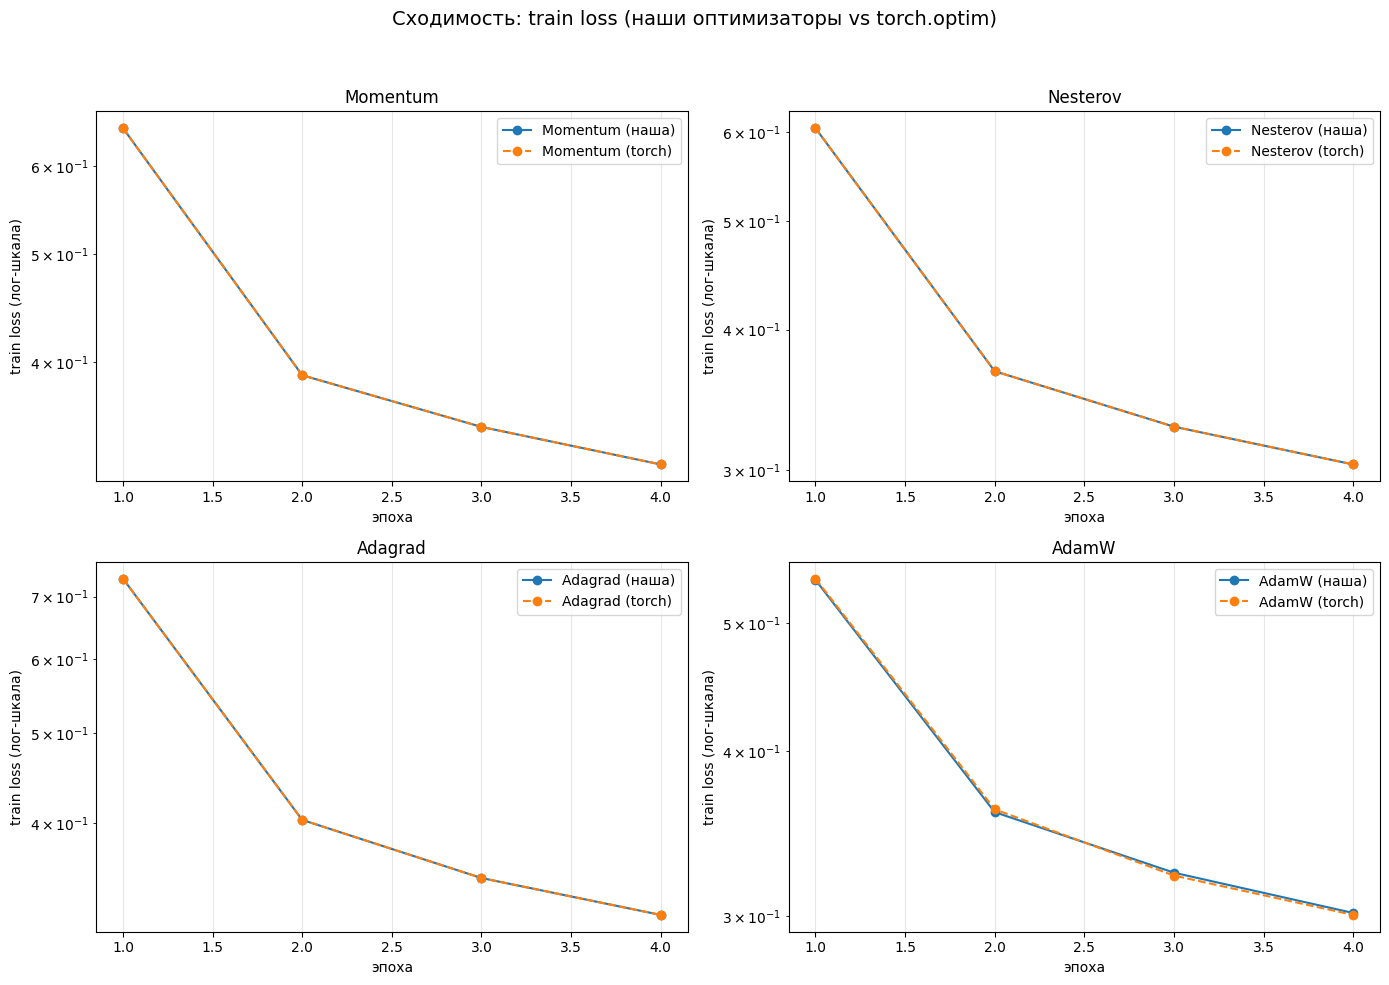

In [13]:
FAMILIES = ["Momentum", "Nesterov", "Adagrad", "AdamW"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, name in zip(axes.flatten(), FAMILIES):
    for variant, style in [("наша", "-"), ("torch", "--")]:
        label = f"{name} ({variant})"
        history = conv_results[label]
        ax.plot(range(1, CONV_EPOCHS + 1), history["train_loss"],
                marker="o", linestyle=style, label=label)
    ax.set_title(name)
    ax.set_xlabel("эпоха")
    ax.set_ylabel("train loss (лог-шкала)")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Сходимость: train loss (наши оптимизаторы vs torch.optim)", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

### График 2. Средняя норма градиента по эпохам

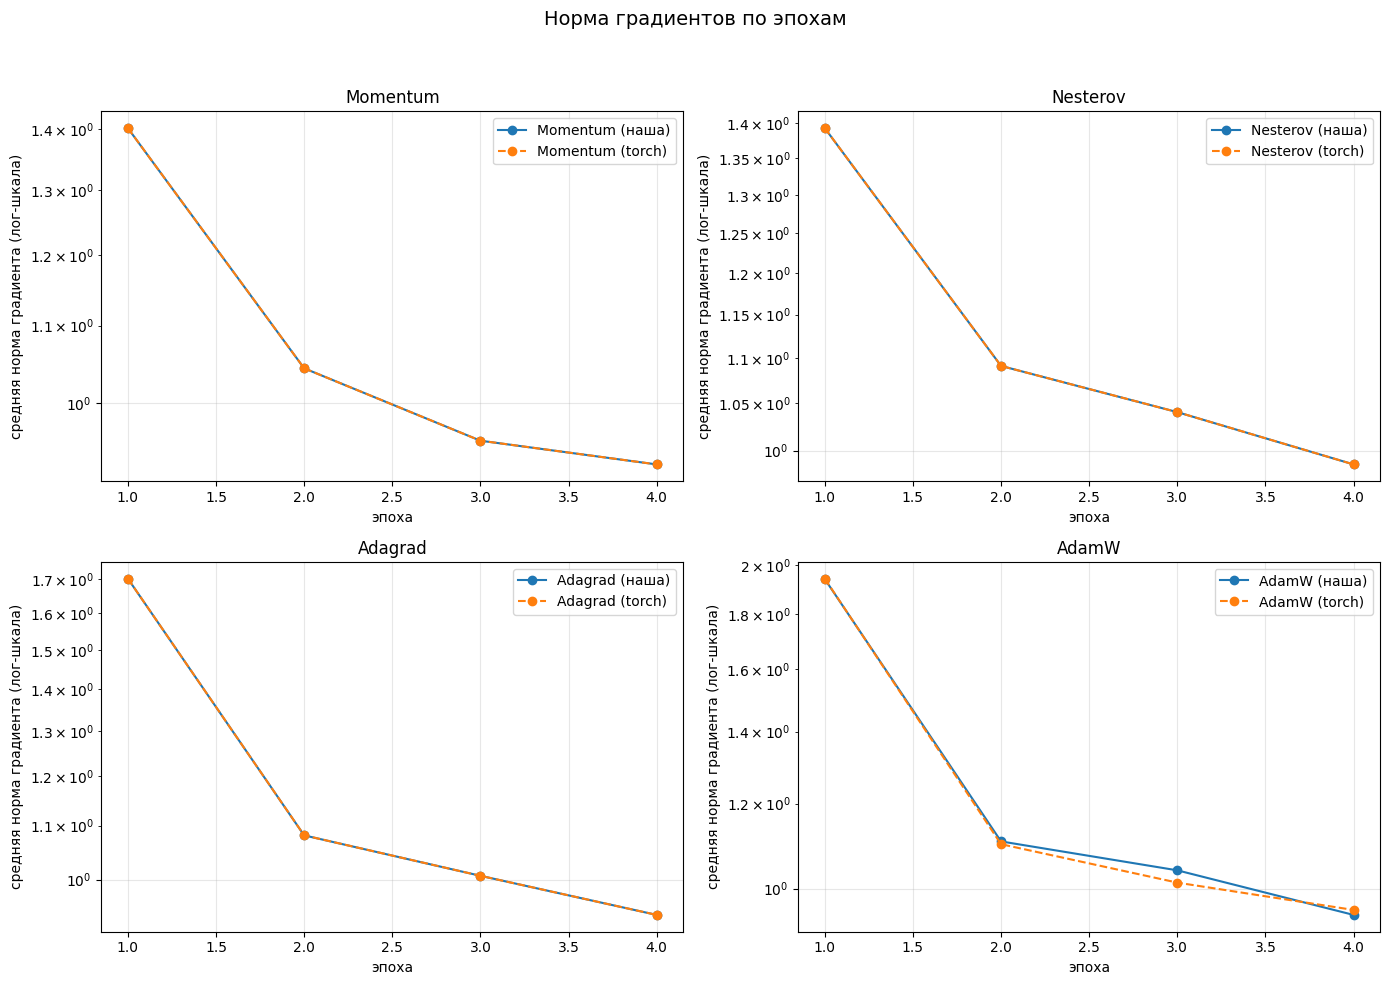

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, name in zip(axes.flatten(), FAMILIES):
    for variant, style in [("наша", "-"), ("torch", "--")]:
        label = f"{name} ({variant})"
        history = conv_results[label]
        ax.plot(range(1, CONV_EPOCHS + 1), history["grad_norm"],
                marker="o", linestyle=style, label=label)
    ax.set_title(name)
    ax.set_xlabel("эпоха")
    ax.set_ylabel("средняя норма градиента (лог-шкала)")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Норма градиентов по эпохам", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

### График 3. Распределения весов после обучения

Для каждого нашего оптимизатора - гистограммы весов всех пяти линейных слоёв.

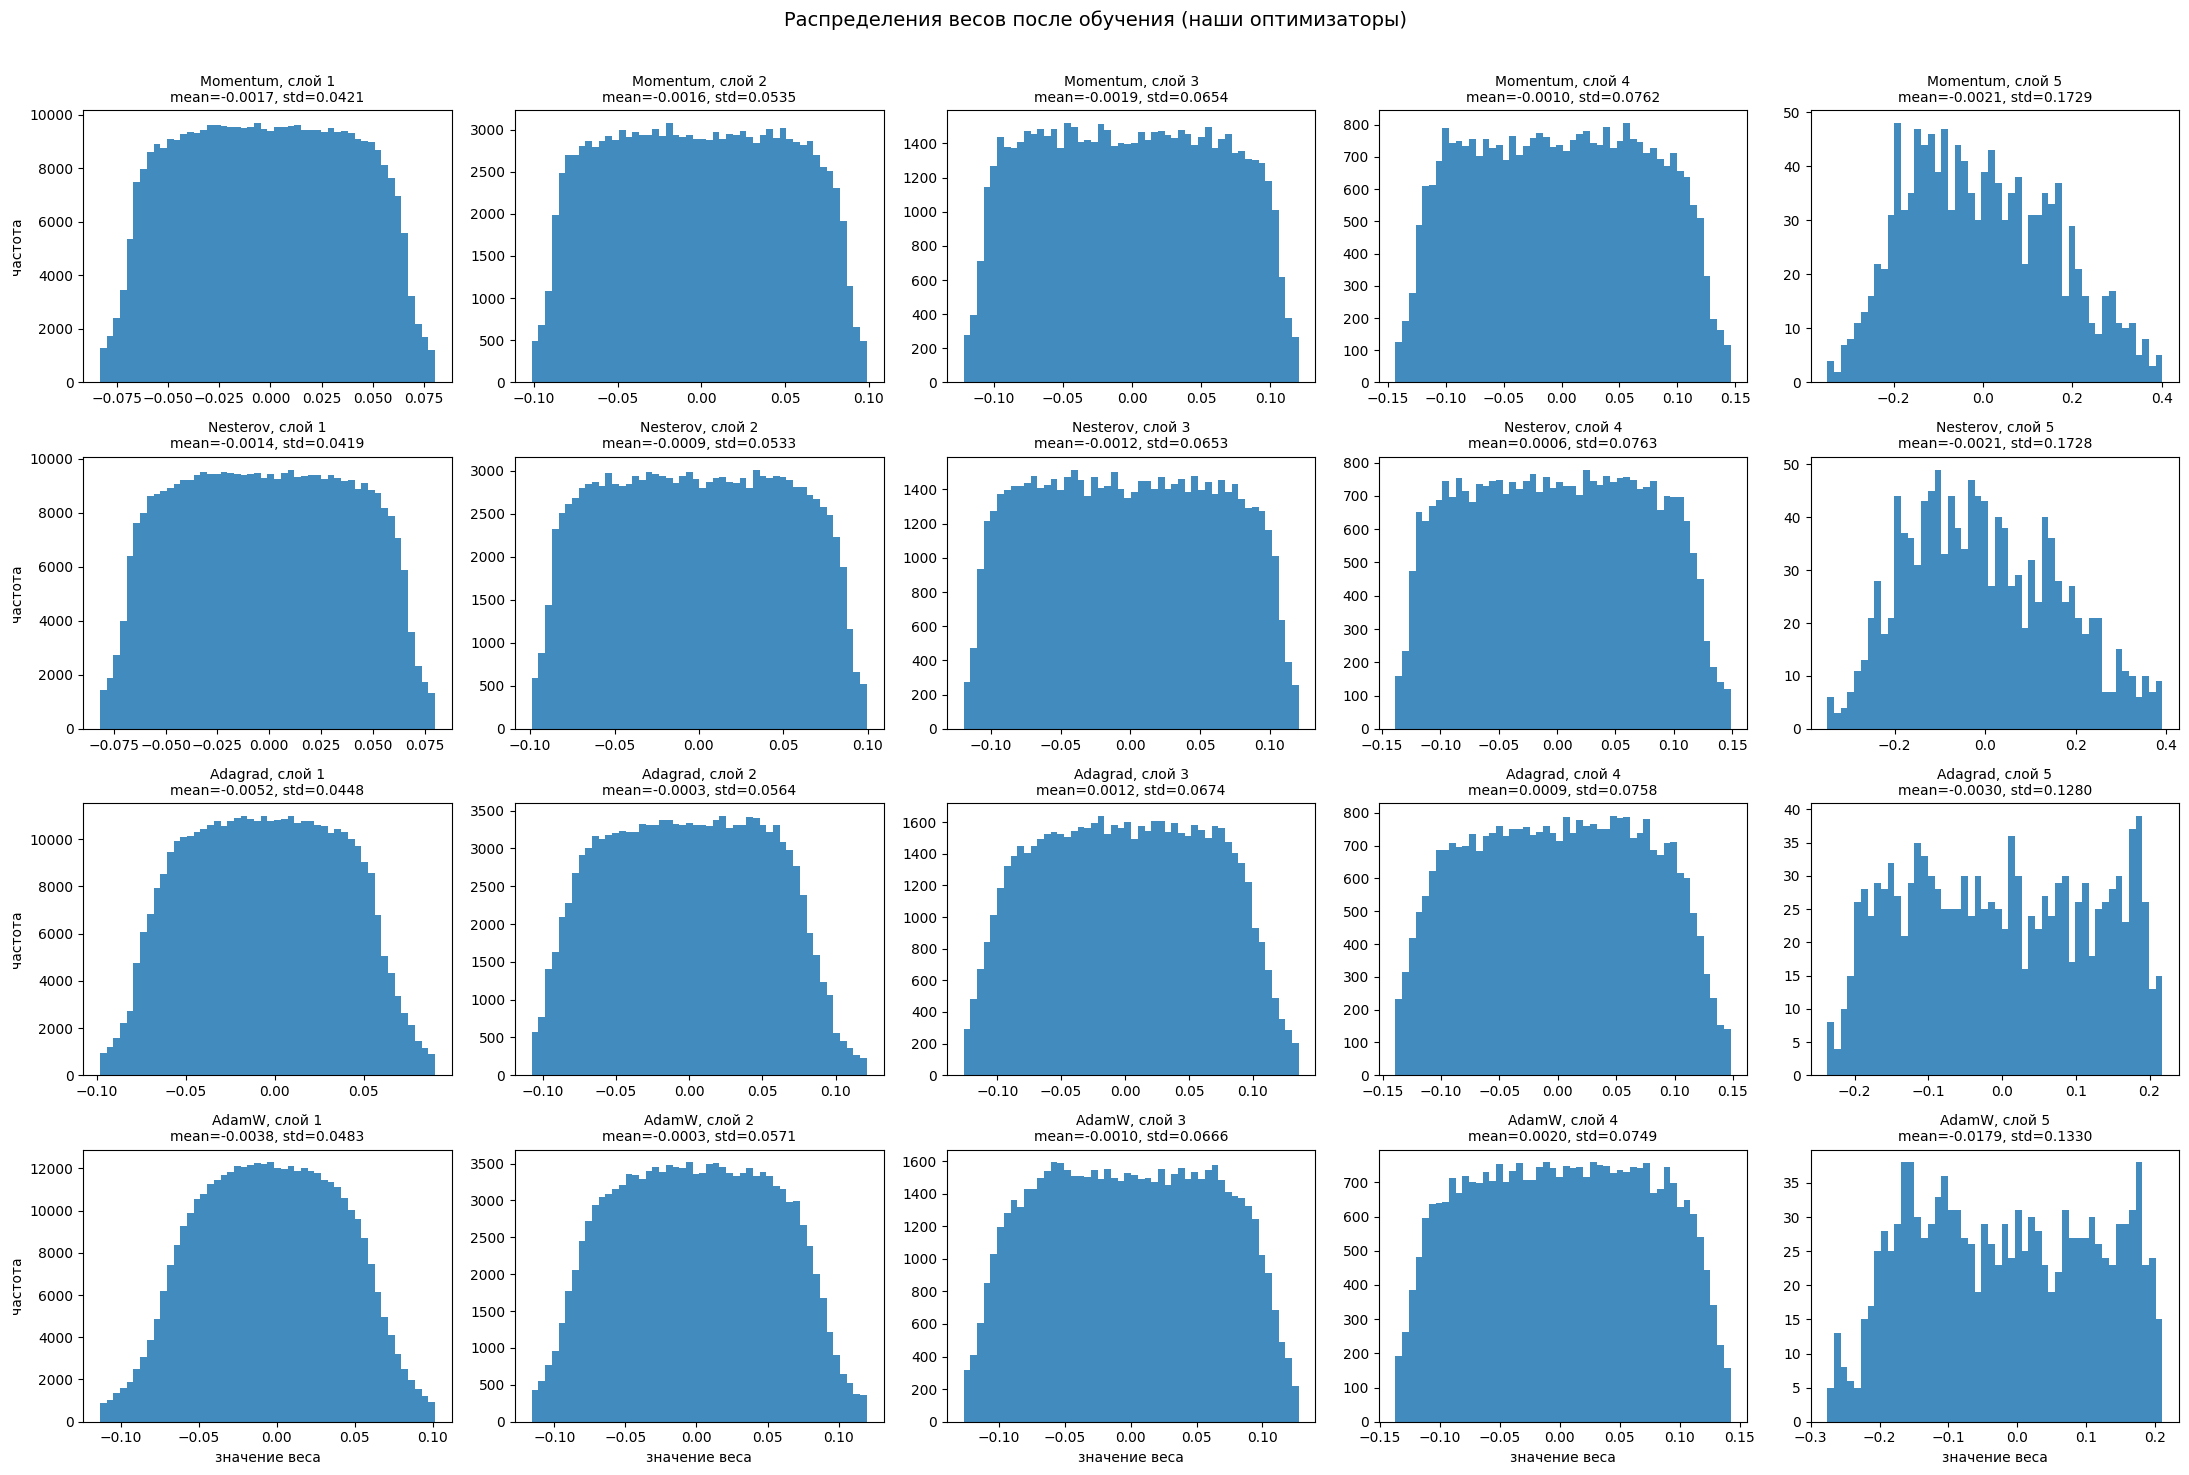

In [15]:
fig, axes = plt.subplots(4, 5, figsize=(22, 15))

for row, name in enumerate(FAMILIES):
    weights = final_weights[name]
    for col, w in enumerate(weights):
        ax = axes[row][col]
        vals = w.flatten().numpy()
        lo, hi = np.percentile(vals, [1, 99])
        ax.hist(vals, bins=50, range=(lo, hi), alpha=0.85)
        ax.set_title(f"{name}, слой {col + 1}\nmean={vals.mean():.4f}, std={vals.std():.4f}",
                     fontsize=10)
        if row == 3:
            ax.set_xlabel("значение веса")
        if col == 0:
            ax.set_ylabel("частота")

fig.suptitle("Распределения весов после обучения (наши оптимизаторы)", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

### Итоговая таблица

In [16]:
rows = []
for label, history in conv_results.items():
    rows.append({
        "оптимизатор": label,
        "train_loss (эп.4)": history["train_loss"][-1],
        "val_loss (эп.4)": history["val_loss"][-1],
        "val_acc (эп.4)": history["val_acc"][-1],
        "средняя норма градиента (эп.4)": history["grad_norm"][-1],
    })

summary = pd.DataFrame(rows)
summary

,оптимизатор,train_loss (эп.4),val_loss (эп.4),val_acc (эп.4),средняя норма градиента (эп.4)
0,Momentum (наша),0.323882,0.373072,0.8623,0.927479
1,Momentum (torch),0.323882,0.373072,0.8623,0.927479
2,Nesterov (наша),0.303340,0.343977,0.8746,0.985817
3,Nesterov (torch),0.303340,0.343977,0.8746,0.985817
4,Adagrad (наша),0.318870,0.351357,0.8754,0.939671
5,Adagrad (torch),0.318870,0.351357,0.8754,0.939671
6,AdamW (наша),0.301669,0.339404,0.8799,0.945104
7,AdamW (torch),0.300648,0.349491,0.8704,0.955221


In [17]:
print("Финальные метрики (наши реализации):")
ours = summary[summary["оптимизатор"].str.contains("наша")]
print(ours.to_string(index=False))

Финальные метрики (наши реализации):
    оптимизатор  train_loss (эп.4)  val_loss (эп.4)  val_acc (эп.4)  средняя норма градиента (эп.4)
Momentum (наша)           0.323882         0.373072          0.8623                        0.927479
Nesterov (наша)           0.303340         0.343977          0.8746                        0.985817
 Adagrad (наша)           0.318870         0.351357          0.8754                        0.939671
   AdamW (наша)           0.301669         0.339404          0.8799                        0.945104


## Выводы

### Тесты

* Все **14 тестов** прошли. Каждый оптимизатор проверен сравнением с эквивалентом из `torch.optim`
  на модельной задаче: траектории параметров совпадают с точностью ~1e-8 (float64) за 25–40 шагов
* Дополнительно проверены: аналитически посчитанный первый шаг (Momentum: 1 -> 0.8, Nesterov: 1 -> 0.62, Adagrad: 1 -> 0.9, AdamW: 1 -> 0.999 без штрафа и 0.99899 со штрафом), эквивалентность Momentum(momentum=0) обычному SGD, а также сходимость всех четырёх алгоритмов на квадратичной задаче

### Сходимость на FashionMNIST (модель из задания 1, ReLU + Xavier, 4 эпохи)

Все четыре реализации успешно обучают сеть, контрольные запуски `torch.optim` с теми же гиперпараметрами дают практически те же кривые (Графики 1–2):

| Оптимизатор | train loss (эп. 4) | val loss (эп. 4) | val acc (эп. 4) |
|-------------|--------------------|------------------|-----------------|
| Momentum    | 0.324 | 0.373 | 0.862 |
| Nesterov    | 0.303 | 0.344 | 0.875 |
| Adagrad     | 0.319 | 0.351 | 0.875 |
| AdamW       | 0.302 | 0.339 | **0.880** |

* Лучший результат - у **AdamW**: адаптивные моменты с поправкой на смещение дают самый быстрый и стабильный старт, и он же показывает минимальный loss на всём протяжении обучения
* **Nesterov** заметно обгоняет обычный Momentum (0.875 против 0.862) - «взгляд вперёд» ускоряет сходимость
* **Adagrad** выходит на тот же уровень (0.875), но его шаг по построению уменьшается с накоплением квадратов градиентов - дальнейший прогресс замедляется
* Значения loss/acc у наших реализаций и у `torch.optim` совпадают в пределах точности печати; для AdamW есть микрорасхождения в 3-м знаке (разный порядок операций во float32, накопленный за ~1900 шагов) - это ожидаемо и на выводы не влияет
* Средняя норма градиента к концу обучения у всех оптимизаторов ≈ 0.93–0.99 (динамика по эпохам - на Графике 2). Распределения весов всех слоёв после обучения - на Графике 3: веса остаются в разумном масштабе, без взрывов